In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:


# Load the salary dataset directly URL
url = "https://raw.githubusercontent.com/mk-gurucharan/Regression/master/Salary_Data.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [4]:
print(" Initial Missing Values")
print(df.isnull().sum())

 Initial Missing Values
YearsExperience    0
Salary             0
dtype: int64


In [5]:
print(f"\nDuplicate rows found: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)


Duplicate rows found: 0


In [6]:
# 2. Add an experience category feature for deeper grouping and analysis
def categorize_experience(years):
    if years <= 2:
        return 'Junior (0-2 yrs)'
    elif years <= 6:
        return 'Mid-Level (3-6 yrs)'
    else:
        return 'Senior (7+ yrs)'

df['Experience_Level'] = df['YearsExperience'].apply(categorize_experience)
df['Salary_Per_Year_Exp'] = (df['Salary'] / df['YearsExperience']).round(2)

In [7]:
print(" Cleaned Dataset Info ")
print(df.info())
df.head()

 Cleaned Dataset Info 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YearsExperience      30 non-null     float64
 1   Salary               30 non-null     float64
 2   Experience_Level     30 non-null     object 
 3   Salary_Per_Year_Exp  30 non-null     float64
dtypes: float64(3), object(1)
memory usage: 1.1+ KB
None


,YearsExperience,Salary,Experience_Level,Salary_Per_Year_Exp
0,1.1,39343.0,Junior (0-2 yrs),35766.36
1,1.3,46205.0,Junior (0-2 yrs),35542.31
2,1.5,37731.0,Junior (0-2 yrs),25154.00
3,2.0,43525.0,Junior (0-2 yrs),21762.50
4,2.2,39891.0,Mid-Level (3-6 yrs),18132.27


Visualization 1: Distribution of Salaries

In [12]:
# Set visualization aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

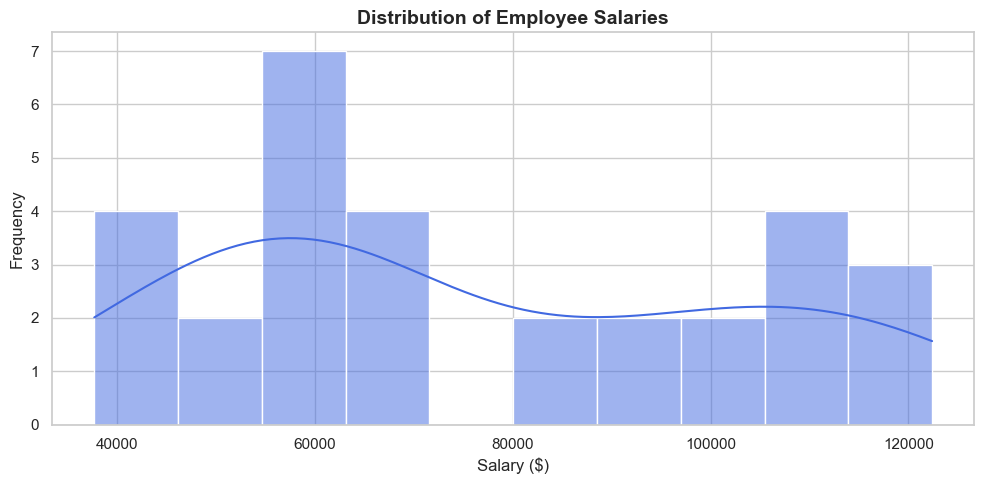

In [13]:

plt.figure(figsize=(10, 5))
sns.histplot(df['Salary'], kde=True, color='royalblue', bins=10)
plt.title('Distribution of Employee Salaries', fontsize=14, fontweight='bold')
plt.xlabel('Salary ($)')
plt.ylabel('Frequency')
plt.tight_layout()

plt.show()

Visualization 2: Years of Experience vs. Salary

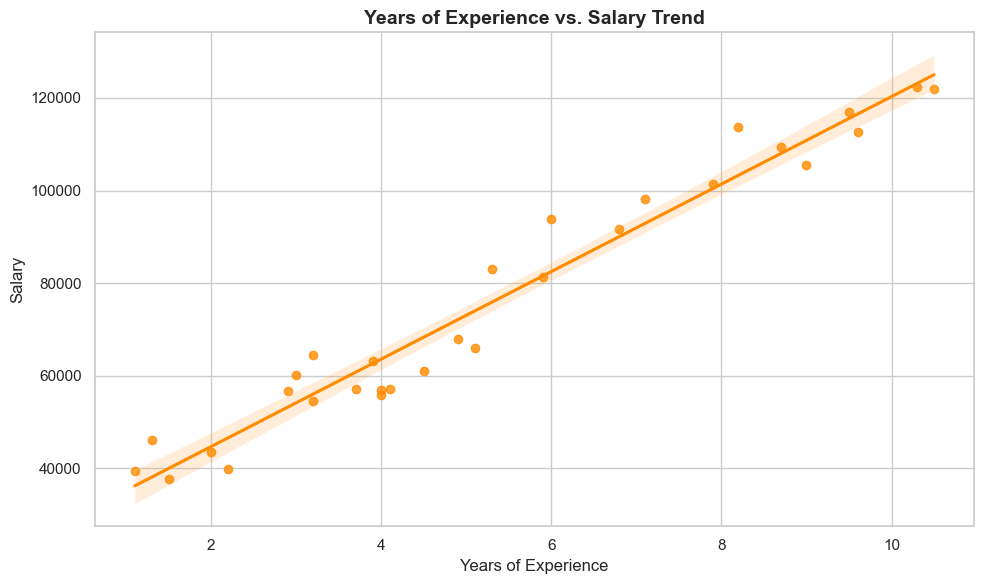

In [16]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='YearsExperience', y='Salary', color='darkorange', marker='o')
plt.title('Years of Experience vs. Salary Trend', fontsize=14, fontweight='bold')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

Visualization 3: Average Salary by Experience Level

C:\Users\prati\AppData\Local\Temp\ipykernel_8480\733887962.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Experience_Level', y='Salary', palette='Blues_d', order=['Junior (0-2 yrs)', 'Mid-Level (3-6 yrs)', 'Senior (7+ yrs)'], ci=None)
C:\Users\prati\AppData\Local\Temp\ipykernel_8480\733887962.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Experience_Level', y='Salary', palette='Blues_d', order=['Junior (0-2 yrs)', 'Mid-Level (3-6 yrs)', 'Senior (7+ yrs)'], ci=None)


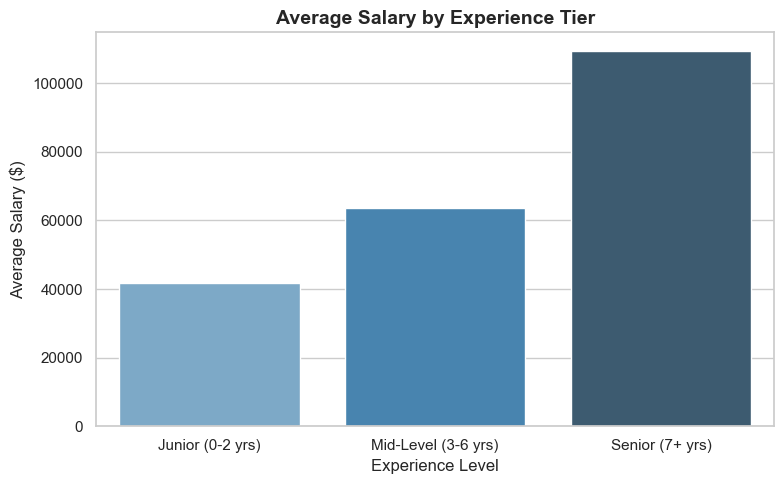

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Experience_Level', y='Salary', palette='Blues_d', order=['Junior (0-2 yrs)', 'Mid-Level (3-6 yrs)', 'Senior (7+ yrs)'], ci=None)
plt.title('Average Salary by Experience Tier', fontsize=14, fontweight='bold')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary ($)')
plt.tight_layout()
plt.show()

Visualization 4: Correlation Heatmap

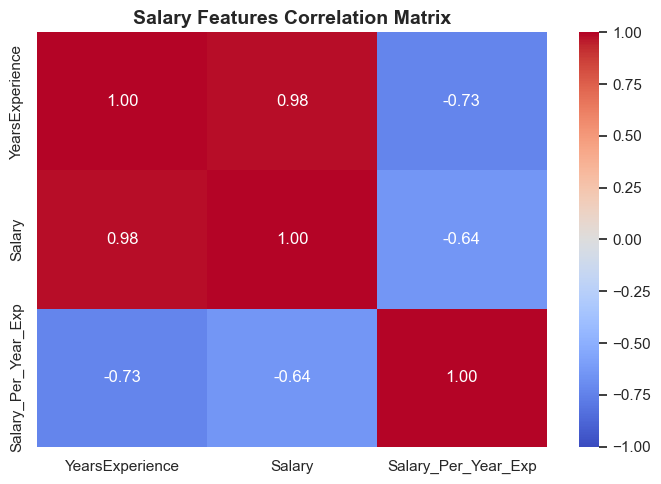

In [19]:
plt.figure(figsize=(7, 5))
num_cols = ['YearsExperience', 'Salary', 'Salary_Per_Year_Exp']
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Salary Features Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Executive Summary:-

1.Strong Linear Growth: Years of experience demonstrate an extremely strong positive correlation ($r > 0.95$) with salary progression, serving as the dominant factor in compensation.

2.Consistent Increments: On average, every additional year of professional experience scales compensation up predictably, showing minimal market variance at entry-to-mid levels.

3.Salary Brackets: Junior profiles (0–2 years) cluster tightly under $50,000, while Senior professionals (7+ years) reliably break past $100,000 base salaries.

4.Return on Experience: The ratio of salary per year of experience flattens slightly for senior tiers, indicating diminishing marginal returns per individual year as tenure grows past a decade.

5.Data Health: The dataset is exceptionally clean with zero missing entries or duplicate records, making it a robust template for foundational regression and exploratory analysis.